# Projeto Integrador — Ciência de Dados Aplicada a Situações de Mercado

## Calculadora de Estimativa de Horas de Implantação de Sistema de Gestão Empresarial (SAP Business One)

**1ª Etapa — Análise Exploratória de Dados**

Este notebook desenvolve a prova de conceito de um modelo de inteligência de negócio para estimar o tempo de implantação de um sistema de gestão empresarial (ERP), com base em características do cliente (número de usuários, filiais, integrações, volume de dados, etc).

**Fonte de dados**

Como não há uma base pública de projetos de implantação SAP Business One, foi construído um dataset fictício, porém estruturado com base em variáveis reais de um documento de *Handover Técnico-Comercial* de projeto de implantação (licenças, ambiente, add-ons, volume de notas fiscais, plano de contas) e na metodologia SAP Accelerated Implementation Program (SAP AIP), metodologia oficial da SAP para implantação do SAP Business One, que estrutura o projeto em cinco fases (Project Preparation, Business Blueprint, Project Realization, Final Preparation e Go-Live and Support).

**Escopo desta etapa**

- Definição da fonte de dados (geração do dataset fictício)
- Definição do escopo de exploração
- Cinco visualizações com Matplotlib
- Justificativa de cada visualização para a tomada de decisão


## 1. Importação das bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


## 2. Definição e geração da fonte de dados

O dataset simula **300 projetos fictícios** de implantação de SAP Business One. As variáveis de entrada seguem os campos observados em um documento real de Handover Técnico-Comercial:

| Variável | Descrição |
|---|---|
| `numero_usuarios` | Quantidade de licenças de usuário (LU) contratadas |
| `numero_filiais` | Quantidade de filiais/unidades do cliente |
| `tipo_ambiente` | Dedicado ou Compartilhado |
| `modalidade` | Cloud ou On Premise |
| `volume_notas_mensal` | Faixa de notas fiscais emitidas por mês |
| `usa_van_bancaria` | Se o cliente utiliza Van Bancária |
| `qtd_addons` | Quantidade de add-ons a instalar (TaxPlus, BankPlus, ContractPlus etc) |
| `plano_contas_customizado` | Se o plano de contas é definido pelo usuário (não padrão) |
| `qtd_modulos` | Quantidade de módulos a implantar (Financeiro, Fiscal, Compras, Vendas, Estoque, CRM) |
| `complexidade_importacao` | Quantidade de tipos de dados a importar (itens, PN, saldos, ativo fixo etc) |

A variável alvo, `horas_totais_implantacao`, é gerada a partir de uma combinação dessas variáveis com pesos coerentes com a prática de consultoria, mais um ruído aleatório e um termo de interação entre usuários e filiais, para simular a variabilidade real entre projetos de perfil semelhante.

In [2]:
n = 300

df = pd.DataFrame({
    'projeto_id': [f'PRJ{1000+i}' for i in range(n)],
    'numero_usuarios': np.random.randint(3, 90, n),
    'numero_filiais': np.random.randint(1, 12, n),
    'tipo_ambiente': np.random.choice(['Dedicado', 'Compartilhado'], n, p=[0.4, 0.6]),
    'modalidade': np.random.choice(['Cloud', 'On Premise'], n, p=[0.7, 0.3]),
    'usa_van_bancaria': np.random.choice(['Sim', 'Não'], n, p=[0.35, 0.65]),
    'qtd_addons': np.random.randint(0, 7, n),
    'plano_contas_customizado': np.random.choice(['Sim', 'Não'], n, p=[0.45, 0.55]),
    'qtd_modulos': np.random.randint(1, 7, n),
    'complexidade_importacao': np.random.randint(1, 11, n),
})

# Faixa de volume de notas fiscais, mesmo padrão de faixas do handover real
notas_mensal = np.random.randint(50, 16000, n)
faixas = pd.cut(
    notas_mensal,
    bins=[0, 1000, 4000, 8000, 15000, np.inf],
    labels=['Até 1.000', '1.001 a 4.000', '4.001 a 8.000', '8.001 a 15.000', 'Acima de 15.000']
)
df['volume_notas_mensal'] = faixas
df['notas_mensal_num'] = notas_mensal  # valor numérico auxiliar para correlação

# --- Geração da variável alvo (horas totais de implantação) ---
base = 80  # horas mínimas de um projeto simples (1 filial, poucos usuários)

horas = (
    base
    + df['numero_usuarios'] * 1.6
    + df['numero_filiais'] * 9
    + (df['numero_usuarios'] * df['numero_filiais']) * 0.15   # interação: cresce mais que linear
    + df['qtd_addons'] * 14
    + df['qtd_modulos'] * 11
    + df['complexidade_importacao'] * 4.5
    + np.where(df['tipo_ambiente'] == 'Dedicado', 18, 0)
    + np.where(df['plano_contas_customizado'] == 'Sim', 22, 0)
    + np.where(df['usa_van_bancaria'] == 'Sim', 12, 0)
    + df['notas_mensal_num'] * 0.003
    + np.random.normal(0, 30, n)   # ruído
)

df['horas_totais_implantacao'] = horas.clip(lower=60).round(1)

df.head(10)


,projeto_id,numero_usuarios,numero_filiais,tipo_ambiente,modalidade,usa_van_bancaria,qtd_addons,plano_contas_customizado,qtd_modulos,complexidade_importacao,volume_notas_mensal,notas_mensal_num,horas_totais_implantacao
0,PRJ1000,54,1,Compartilhado,Cloud,Não,4,Não,4,3,8.001 a 15.000,9815,273.4
1,PRJ1001,17,5,Compartilhado,On Premise,Não,1,Sim,3,7,8.001 a 15.000,14149,264.4
2,PRJ1002,74,3,Compartilhado,Cloud,Não,4,Não,2,10,8.001 a 15.000,12842,395.1
3,PRJ1003,63,4,Dedicado,Cloud,Não,6,Não,6,5,1.001 a 4.000,3790,443.2
4,PRJ1004,23,3,Dedicado,On Premise,Sim,0,Sim,5,8,8.001 a 15.000,12516,301.8
5,PRJ1005,85,1,Compartilhado,On Premise,Sim,2,Sim,5,1,8.001 a 15.000,12469,395.6
6,PRJ1006,89,1,Dedicado,Cloud,Não,1,Sim,4,3,1.001 a 4.000,1896,349.5
7,PRJ1007,77,5,Compartilhado,On Premise,Sim,3,Sim,2,3,1.001 a 4.000,1528,454.2
8,PRJ1008,77,6,Dedicado,Cloud,Sim,5,Não,3,9,8.001 a 15.000,10637,517.7
9,PRJ1009,26,3,Compartilhado,On Premise,Sim,6,Sim,2,5,8.001 a 15.000,14925,299.0


## 3. Escopo da exploração dos dados

A análise exploratória se concentra em responder três perguntas de negócio, que são exatamente as dúvidas que hoje uma consultoria resolve "no olho" ao montar uma proposta comercial.

1. Quais características do cliente mais impactam o total de horas de implantação?
2. O ambiente contratado (dedicado ou compartilhado) muda a estimativa de esforço?
3. Como as horas totais se distribuem entre as fases do projeto, seguindo a metodologia SAP AIP (Project Preparation, Business Blueprint, Project Realization, Final Preparation e Go-Live and Support)?

As respostas embasam diretamente as variáveis de entrada que um futuro modelo de aprendizado de máquina deveria receber para estimar o esforço de um novo projeto.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   projeto_id                300 non-null    str     
 1   numero_usuarios           300 non-null    int64   
 2   numero_filiais            300 non-null    int64   
 3   tipo_ambiente             300 non-null    str     
 4   modalidade                300 non-null    str     
 5   usa_van_bancaria          300 non-null    str     
 6   qtd_addons                300 non-null    int64   
 7   plano_contas_customizado  300 non-null    str     
 8   qtd_modulos               300 non-null    int64   
 9   complexidade_importacao   300 non-null    int64   
 10  volume_notas_mensal       300 non-null    category
 11  notas_mensal_num          300 non-null    int64   
 12  horas_totais_implantacao  300 non-null    float64 
dtypes: category(1), float64(1), int64(6), str(5)
memory usage: 28

In [4]:
df.describe(include='number').round(2)

,numero_usuarios,numero_filiais,qtd_addons,qtd_modulos,complexidade_importacao,notas_mensal_num,horas_totais_implantacao
count,300.00,300.00,300.00,300.00,300.00,300.00,300.00
mean,43.63,5.83,3.04,3.66,5.47,7645.37,395.86
std,25.21,3.13,2.02,1.70,2.79,4662.05,97.54
min,3.00,1.00,0.00,1.00,1.00,56.00,199.60
25%,22.00,3.00,1.00,2.00,3.00,3537.75,323.68
50%,43.00,6.00,3.00,4.00,5.00,7078.50,387.05
75%,64.00,9.00,5.00,5.00,8.00,11841.25,459.33
max,89.00,11.00,6.00,6.00,10.00,15993.00,705.10


In [5]:
df.describe(include='object')

/tmp/ipykernel_475/87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,projeto_id,tipo_ambiente,modalidade,usa_van_bancaria,plano_contas_customizado
count,300,300,300,300,300
unique,300,2,2,2,2
top,PRJ1000,Compartilhado,Cloud,Não,Não
freq,1,175,212,195,165


## 4. Visualizações

### Visualização 1 — Dispersão: número de usuários x horas de implantação

Mostra a relação entre o tamanho da base de usuários e o esforço total do projeto, separando por modalidade (Cloud x On Premise).

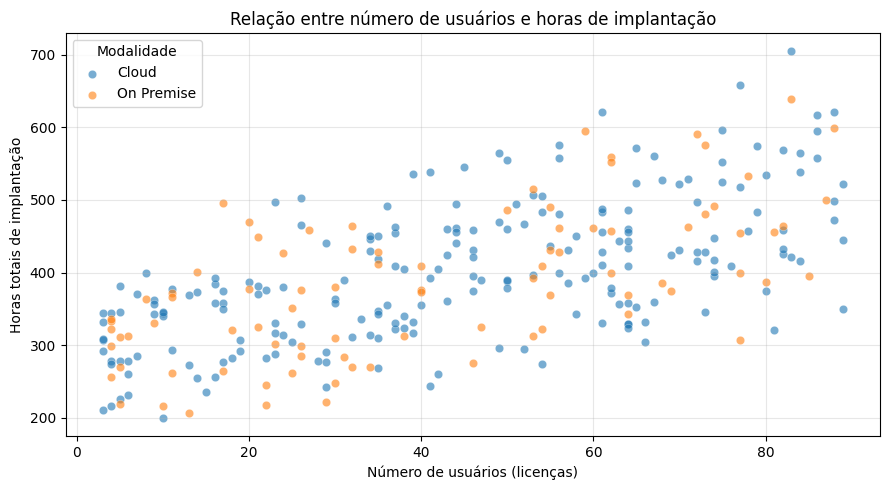

In [6]:
fig, ax = plt.subplots()

for modalidade, cor in zip(['Cloud', 'On Premise'], ['#1f77b4', '#ff7f0e']):
    subset = df[df['modalidade'] == modalidade]
    ax.scatter(subset['numero_usuarios'], subset['horas_totais_implantacao'],
               alpha=0.6, label=modalidade, color=cor, edgecolor='white', linewidth=0.3)

ax.set_xlabel('Número de usuários (licenças)')
ax.set_ylabel('Horas totais de implantação')
ax.set_title('Relação entre número de usuários e horas de implantação')
ax.legend(title='Modalidade')
plt.tight_layout()
plt.show()


**Como auxilia a tomada de decisão**

Permite à consultoria visualizar, de forma imediata, a faixa de horas esperada para um cliente com determinado número de usuários, servindo de primeira referência para o dimensionamento de propostas comerciais. A distinção por modalidade também evidencia se projetos Cloud tendem a demandar mais ou menos esforço do que projetos On Premise, informação relevante para precificação diferenciada.

### Visualização 2 — Boxplot: horas de implantação por tipo de ambiente

Compara a distribuição de horas entre projetos com ambiente Dedicado e Compartilhado.

/tmp/ipykernel_475/2322086991.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(dados_ambiente, labels=['Dedicado', 'Compartilhado'], patch_artist=True)


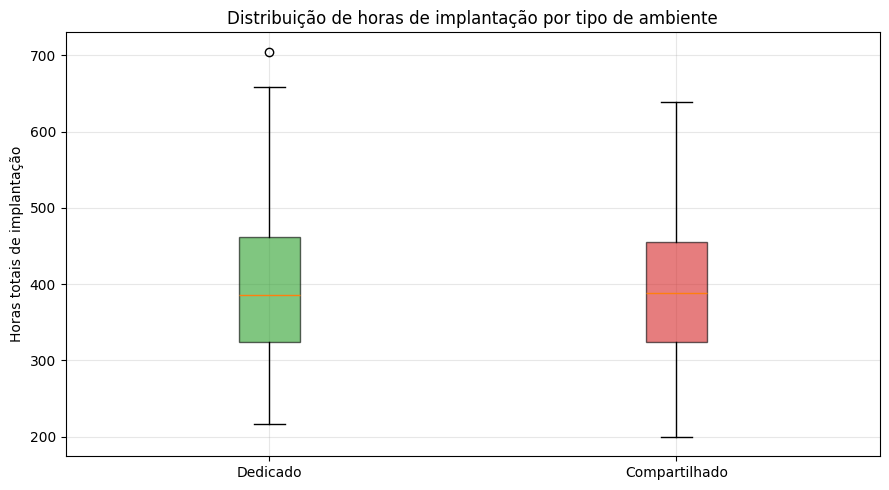

In [7]:
fig, ax = plt.subplots()

dados_ambiente = [
    df.loc[df['tipo_ambiente'] == 'Dedicado', 'horas_totais_implantacao'],
    df.loc[df['tipo_ambiente'] == 'Compartilhado', 'horas_totais_implantacao'],
]

box = ax.boxplot(dados_ambiente, labels=['Dedicado', 'Compartilhado'], patch_artist=True)
for patch, cor in zip(box['boxes'], ['#2ca02c', '#d62728']):
    patch.set_facecolor(cor)
    patch.set_alpha(0.6)

ax.set_ylabel('Horas totais de implantação')
ax.set_title('Distribuição de horas de implantação por tipo de ambiente')
plt.tight_layout()
plt.show()


**Como auxilia a tomada de decisão**

Evidencia se a escolha de infraestrutura do cliente (ambiente dedicado versus compartilhado) altera de forma consistente o esforço de implantação, e não apenas a média, mas também a dispersão e eventuais valores atípicos. Isso ajuda a equipe comercial a justificar ao cliente diferenças de prazo ou de custo associadas ao tipo de ambiente contratado.

### Visualização 3 — Barras: média de horas por quantidade de add-ons

Mostra como a média de horas de implantação cresce conforme aumenta o número de add-ons instalados.

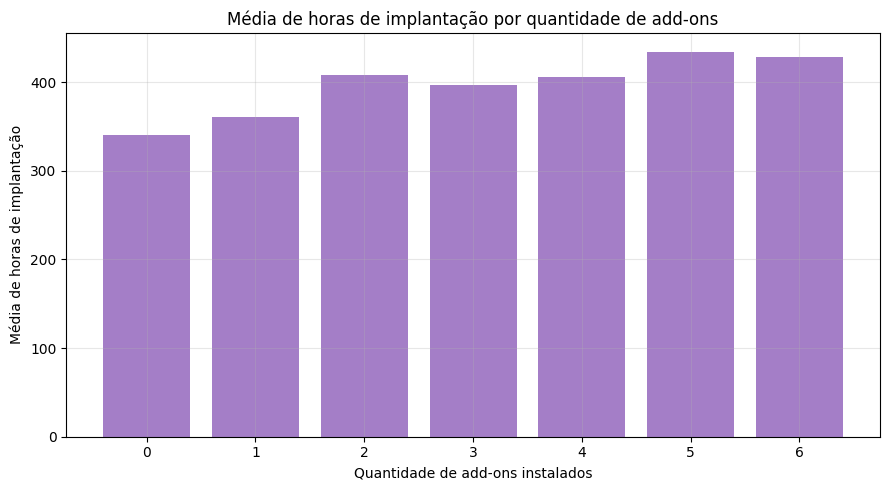

In [8]:
media_por_addon = df.groupby('qtd_addons')['horas_totais_implantacao'].mean()

fig, ax = plt.subplots()
ax.bar(media_por_addon.index, media_por_addon.values, color='#9467bd', alpha=0.85)

ax.set_xlabel('Quantidade de add-ons instalados')
ax.set_ylabel('Média de horas de implantação')
ax.set_title('Média de horas de implantação por quantidade de add-ons')
ax.set_xticks(media_por_addon.index)
plt.tight_layout()
plt.show()


**Como auxilia a tomada de decisão**

Quantifica o impacto médio de cada add-on adicional (TaxPlus, BankPlus, ContractPlus, entre outros) no esforço total. É uma informação direta para o time de vendas ajustar a proposta comercial assim que o escopo de add-ons é definido com o cliente, evitando estimativas subestimadas para projetos com muitas integrações.

### Visualização 4 — Heatmap de correlação entre as variáveis

Mostra a força da relação linear entre cada variável numérica e as horas totais de implantação.

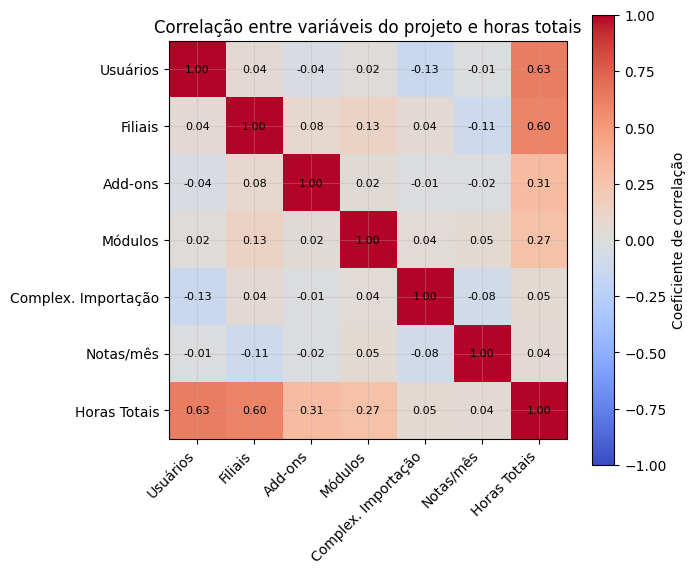

In [9]:
df_corr = df[['numero_usuarios', 'numero_filiais', 'qtd_addons', 'qtd_modulos',
              'complexidade_importacao', 'notas_mensal_num', 'horas_totais_implantacao']].copy()
df_corr.columns = ['Usuários', 'Filiais', 'Add-ons', 'Módulos',
                    'Complex. Importação', 'Notas/mês', 'Horas Totais']

corr = df_corr.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='black', fontsize=8)

fig.colorbar(im, ax=ax, label='Coeficiente de correlação')
ax.set_title('Correlação entre variáveis do projeto e horas totais')
plt.tight_layout()
plt.show()


**Como auxilia a tomada de decisão**

Aponta objetivamente quais variáveis mais se relacionam com o esforço total, orientando quais informações devem ser priorizadas em um handover técnico-comercial e quais entradas o futuro modelo de aprendizado de máquina deve considerar com mais peso. Reduz a estimativa "no olho" ao substituir a percepção subjetiva do consultor por evidência quantitativa.

### Visualização 5 — Distribuição média de horas por fase do projeto (metodologia SAP AIP)

Com base na metodologia SAP Accelerated Implementation Program (SAP AIP), metodologia oficial da SAP para implantação do SAP Business One, as horas totais de cada projeto fictício são distribuídas proporcionalmente entre as cinco fases da metodologia.

- **Project Preparation**, transferência a partir de vendas, plano do projeto e reunião de kick-off
- **Business Blueprint**, workshops de análise dos processos de negócio e documentação da solução
- **Project Realization**, configuração do sistema, importação de cadastros e testes, núcleo do projeto
- **Final Preparation**, treinamento de usuários e atividades de cutover
- **Go-Live and Support**, acompanhamento do início de operação e resolução de problemas pendentes

/tmp/ipykernel_475/96355516.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(media_fases.index, rotation=30, ha='right')


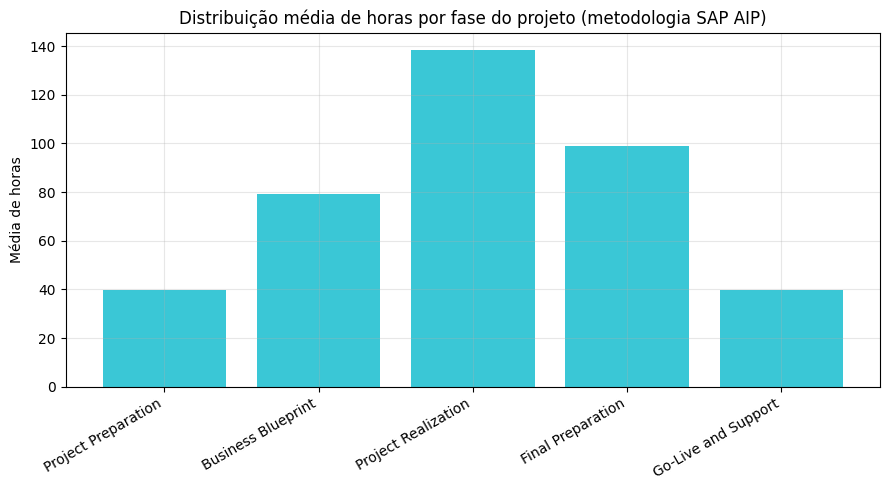

In [10]:
fases = {
    'Project Preparation': 0.10,
    'Business Blueprint': 0.20,
    'Project Realization': 0.35,
    'Final Preparation': 0.25,
    'Go-Live and Support': 0.10,
}

for fase, peso in fases.items():
    df[fase] = df['horas_totais_implantacao'] * peso

media_fases = df[list(fases.keys())].mean()

fig, ax = plt.subplots()
ax.bar(media_fases.index, media_fases.values, color='#17becf', alpha=0.85)

ax.set_ylabel('Média de horas')
ax.set_title('Distribuição média de horas por fase do projeto (metodologia SAP AIP)')
ax.set_xticklabels(media_fases.index, rotation=30, ha='right')
plt.tight_layout()
plt.show()


**Como auxilia a tomada de decisão**

Traduz a estimativa total de horas em um cronograma prático organizado pelas fases da metodologia SAP AIP, a mesma referência oficial usada pela SAP e por seus parceiros de implementação. Isso permite transformar a saída do modelo de aprendizado de máquina diretamente em uma proposta de cronograma para o cliente, e não apenas em um número solto de horas, aproximando a prova de conceito da metodologia real de projetos de implantação SAP Business One.

## 5. Considerações sobre a 1ª etapa

A análise exploratória indica que o número de usuários, a quantidade de filiais, o número de add-ons e a quantidade de módulos implantados são as variáveis com maior relação com o total de horas de implantação, o que reforça sua relevância como entradas do futuro modelo de aprendizado de máquina.

Para a 2ª etapa, o próximo passo é estruturar o modelo de dados relacional (elicitação de entidades e diagrama entidade-relacionamento) a partir dessas variáveis, além de treinar um modelo preditivo (por exemplo, regressão) sobre este dataset, comparando sua estimativa com o esforço "no olho" atualmente praticado.